# 02 Construcción de episodios de urgencias 

In [9]:
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.db import consultar, hash_sql
from src.episodios import (
    construir_episodios,
    preparar_visitas,
    reportar_edades,
    resumen_sensibilidad,
    valores_comparables,
)
from src.graficos import (
    COLORES_GRUPO,
    ETIQUETAS_GRUPO,
    GRISES_TECNICOS,
    TEXTO_SECUNDARIO,
    aplicar_estilo,
    guardar_figura,
    rotular_barras,
)
from src.privacidad import enmascarar_pequenos, suprimir_pequenos, tabla_segura, verificar_agregada

aplicar_estilo()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

## 1. Extracción de visitas de urgencias

In [10]:
visitas_crudas = consultar('visitas_urgencias')
print('Filas y columnas:', visitas_crudas.shape)
print(visitas_crudas.dtypes)

Filas y columnas: (543648, 13)
visit_occurrence_id             int64
person_id                       int64
llegada                datetime64[us]
fin                    datetime64[us]
fin_urg                datetime64[us]
inicio_piso            datetime64[us]
fin_piso               datetime64[us]
hosp                             bool
tiene_9203                       bool
n_segmentos                     int64
n_desplazados                   int64
year_of_birth                   int64
sexo                              str
dtype: object


In [11]:
resumen_extraccion = pd.DataFrame(
    {
        'n_visitas': [len(visitas_crudas)],
        'n_pacientes': [visitas_crudas['person_id'].nunique()],
        'pct_con_desplazados': [100 * visitas_crudas['n_desplazados'].gt(0).mean()],
        'pct_hospitalizadas': [100 * visitas_crudas['hosp'].eq(True).mean()],
        'pct_sin_etapa_9203_valida': [100 * (~visitas_crudas['tiene_9203'].eq(True)).mean()],
    },
    index=pd.Index(['visitas_urgencias'], name='extraccion'),
)
tabla_segura(resumen_extraccion)

,n_visitas,n_pacientes,pct_con_desplazados,pct_hospitalizadas,pct_sin_etapa_9203_valida
extraccion,,,,,
visitas_urgencias,543648,220900,45.77,8.78,28.99


## 2. Preparación y edades

`preparar_visitas` ajusta tipos, calcula la edad al llegar (D8) y el grupo etario. Las edades negativas o mayores a 110 años quedan como `NaN`.

In [12]:
visitas = preparar_visitas(visitas_crudas)
del visitas_crudas
tabla_segura(reportar_edades(visitas))

,n_visitas,pct_visitas
estado_edad,,
valida,543625,100.0
mayor_110,22,0.0
negativa,<10,suprimido


In [13]:
perfil = pd.crosstab(visitas['grupo_etario'], visitas['sexo'])
suprimir_pequenos(perfil, list(perfil.columns))

sexo,femenino,masculino,otro_o_sin_dato
grupo_etario,,,
adulto,200751,138139,32
adulto_mayor,37125,27621,<10
pediatria,66581,73339,33
sin_dato,<10,<10,17


## 3. Sensibilidad al umbral de fusión

Se construyen los episodios con 30, 60 y 120 minutos (D4). La reconsulta a 72 h se reporta sin censura y con censura (D7).

In [14]:
sensibilidad = resumen_sensibilidad(visitas, config.UMBRALES_SENSIBILIDAD)
tabla_segura(sensibilidad)

,n_episodios,pct_hospitalizados,pct_multivisita,max_visitas_episodio,n_1_contacto_breve,n_2_no_hosp_atencion,n_3_hosp_con_hora_piso,n_4_hosp_sin_hora_piso,mediana_los_g3_h,pct_mas_12h_g3,pct_reconsulta_72h_sin_censura,pct_reconsulta_72h_con_censura
umbral_min,,,,,,,,,,,,
30,444757,9.60,21.49,12,208210,193869,36382,6296,24.02,68.15,6.39,6.40
60,440202,9.69,22.71,12,203136,194392,36382,6292,24.02,68.16,5.42,5.43
120,437704,9.75,23.38,12,200322,194712,36382,6288,24.03,68.17,4.88,4.89


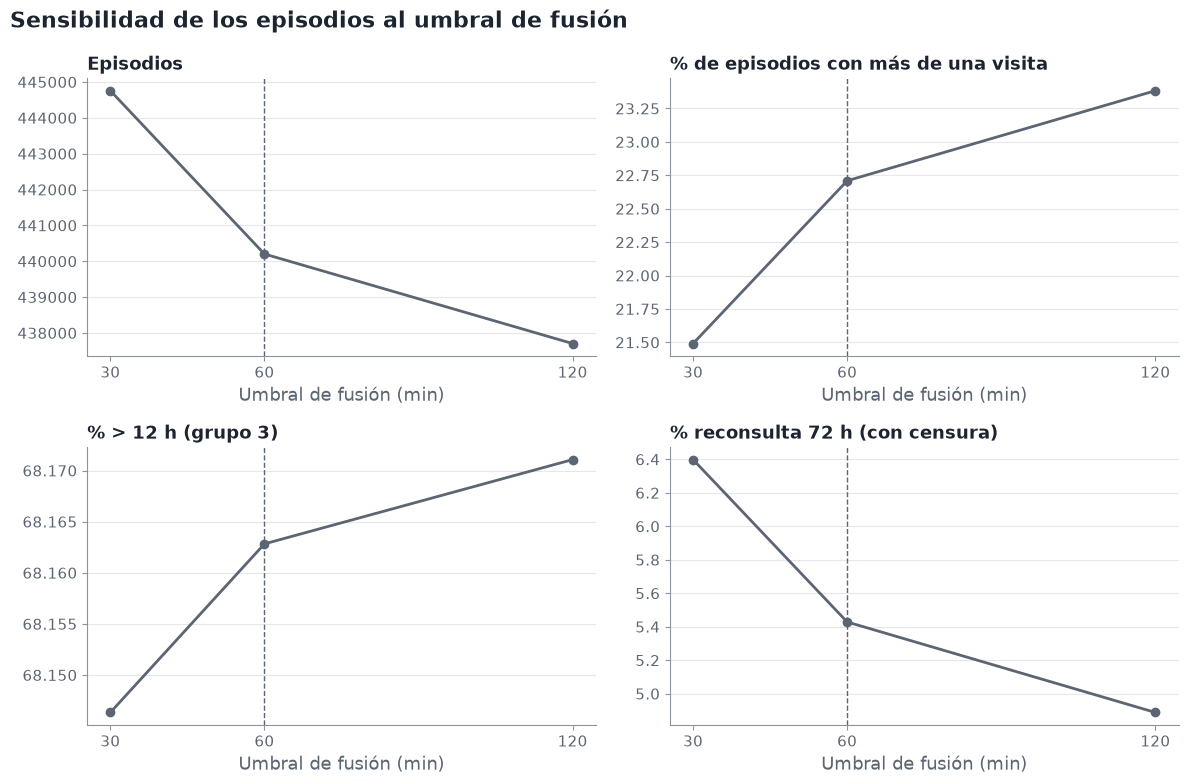

In [15]:
metricas = {
    'n_episodios': 'Episodios',
    'pct_multivisita': '% de episodios con más de una visita',
    'pct_mas_12h_g3': '% > 12 h (grupo 3)',
    'pct_reconsulta_72h_con_censura': '% reconsulta 72 h (con censura)',
}
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (columna, titulo) in zip(ejes.ravel(), metricas.items()):
    ax.plot(sensibilidad.index, sensibilidad[columna], marker='o', color=GRISES_TECNICOS[1])
    ax.axvline(config.UMBRAL_FUSION_MIN, color=TEXTO_SECUNDARIO, linestyle='--', linewidth=1)
    ax.set_xticks(list(sensibilidad.index))
    ax.set_xlabel('Umbral de fusión (min)')
    ax.set_title(titulo, fontsize=13)
fig.suptitle('Sensibilidad de los episodios al umbral de fusión', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar_figura(fig, '02_sensibilidad_umbral')
plt.show()

## 4. Comparación con los valores de referencia de SQL (umbral de 60 min)

Valores de referencia obtenidos en DBeaver el 24-10-2026 (ver `config.REFERENCIA_SQL_60MIN`): 440.202 episodios (397.528 no hospitalizados y 42.674 hospitalizados), 6.290 hospitalizados sin hora de piso, 36.382 con hora de piso válida, y reconsulta a 72 h sin censura de 5,65 % en no hospitalizados y 3,27 % en hospitalizados. Con pandas pueden variar levemente; si alguna diferencia supera el 1 % se emite una advertencia (sin detener la ejecución).

In [16]:
episodios = construir_episodios(visitas, config.UMBRAL_FUSION_MIN)

comparacion = pd.DataFrame(
    {
        'esperado_sql': pd.Series(config.REFERENCIA_SQL_60MIN, dtype=float),
        'obtenido_pandas': pd.Series(valores_comparables(episodios), dtype=float),
    }
).rename_axis('metrica')
comparacion['diferencia_pct'] = (
    100 * (comparacion['obtenido_pandas'] - comparacion['esperado_sql']) / comparacion['esperado_sql']
)
verificar_agregada(comparacion)

for metrica, diferencia in comparacion['diferencia_pct'].items():
    if abs(diferencia) > config.TOLERANCIA_REFERENCIA_PCT:
        warnings.warn(
            f'{metrica}: diferencia de {diferencia:.2f} % frente a la referencia de SQL '
            f'(tolerancia {config.TOLERANCIA_REFERENCIA_PCT} %).'
        )
comparacion.round(3)

,esperado_sql,obtenido_pandas,diferencia_pct
metrica,,,
episodios,440202.00,440202.000,0.000
no_hospitalizados,397528.00,397528.000,0.000
hospitalizados,42674.00,42674.000,0.000
hosp_sin_hora_piso,6290.00,6290.000,0.000
hosp_con_hora_piso_valida,36382.00,36382.000,0.000
pct_reconsulta_72h_no_hosp_sin_censura,5.65,5.653,0.052
pct_reconsulta_72h_hosp_sin_censura,3.27,3.269,-0.032


## 5. Episodios finales (umbral de 60 min)

Tamaño de cada grupo de análisis (D6), episodios con LOS nulo y número de visitas fusionadas por episodio.

In [17]:
tamano_grupos = (
    episodios['grupo'].value_counts()
    .reindex(list(config.GRUPOS), fill_value=0)
    .rename_axis('grupo')
    .rename('n_episodios')
    .to_frame()
)
tamano_grupos['pct_episodios'] = 100 * tamano_grupos['n_episodios'] / tamano_grupos['n_episodios'].sum()
tamano_grupos['n_los_nulo'] = (
    episodios['los_h'].isna().groupby(episodios['grupo']).sum().reindex(tamano_grupos.index, fill_value=0)
)
tabla_segura(tamano_grupos)

,n_episodios,pct_episodios,n_los_nulo
grupo,,,
1_contacto_breve,203136,46.15,<10
2_no_hosp_atencion,194392,44.16,<10
3_hosp_con_hora_piso,36382,8.26,<10
4_hosp_sin_hora_piso,6292,1.43,6292


In [18]:
visitas_por_episodio = (
    episodios['n_visitas'].clip(upper=4).map({1: '1', 2: '2', 3: '3', 4: '4 o más'})
    .value_counts().sort_index().rename_axis('visitas_por_episodio').rename('n_episodios').to_frame()
)
visitas_por_episodio['pct_episodios'] = (
    100 * visitas_por_episodio['n_episodios'] / visitas_por_episodio['n_episodios'].sum()
)
tabla_segura(visitas_por_episodio)

,n_episodios,pct_episodios
visitas_por_episodio,,
1,340236,77.29
2,97131,22.07
3,2273,0.52
4 o más,562,0.13


## 6. Hospitalizados con y sin hora de piso (grupos 3 y 4)

Los tiempos solo se analizan en el grupo 3. Si los grupos 3 y 4 tienen perfiles parecidos por grupo etario, sexo y año de llegada, excluir el grupo 4 no debería sesgar mucho el LOS de los hospitalizados.

In [19]:
hospitalizados = episodios[episodios['grupo'].isin([config.GRUPOS[2], config.GRUPOS[3]])].assign(
    anio_llegada=lambda d: d['llegada'].dt.year
)
for variable in ['grupo_etario', 'sexo', 'anio_llegada']:
    conteos = pd.crosstab(hospitalizados[variable], hospitalizados['grupo'])
    porcentajes = 100 * conteos / conteos.sum()
    tabla = conteos.add_prefix('n_').join(porcentajes.add_prefix('pct_'))
    display(tabla_segura(tabla, decimales=1))

grupo,n_3_hosp_con_hora_piso,n_4_hosp_sin_hora_piso,pct_3_hosp_con_hora_piso,pct_4_hosp_sin_hora_piso
grupo_etario,,,,
adulto,21236,4067,58.4,64.6
adulto_mayor,7258,617,19.9,9.8
pediatria,7888,1608,21.7,25.6


grupo,n_3_hosp_con_hora_piso,n_4_hosp_sin_hora_piso,pct_3_hosp_con_hora_piso,pct_4_hosp_sin_hora_piso
sexo,,,,
femenino,20724,3585,57.0,57.0
masculino,15658,2707,43.0,43.0


grupo,n_3_hosp_con_hora_piso,n_4_hosp_sin_hora_piso,pct_3_hosp_con_hora_piso,pct_4_hosp_sin_hora_piso
anio_llegada,,,,
2023,11452,2044,31.5,32.5
2024,10631,1932,29.2,30.7
2025,10244,1666,28.2,26.5
2026,4055,650,11.1,10.3


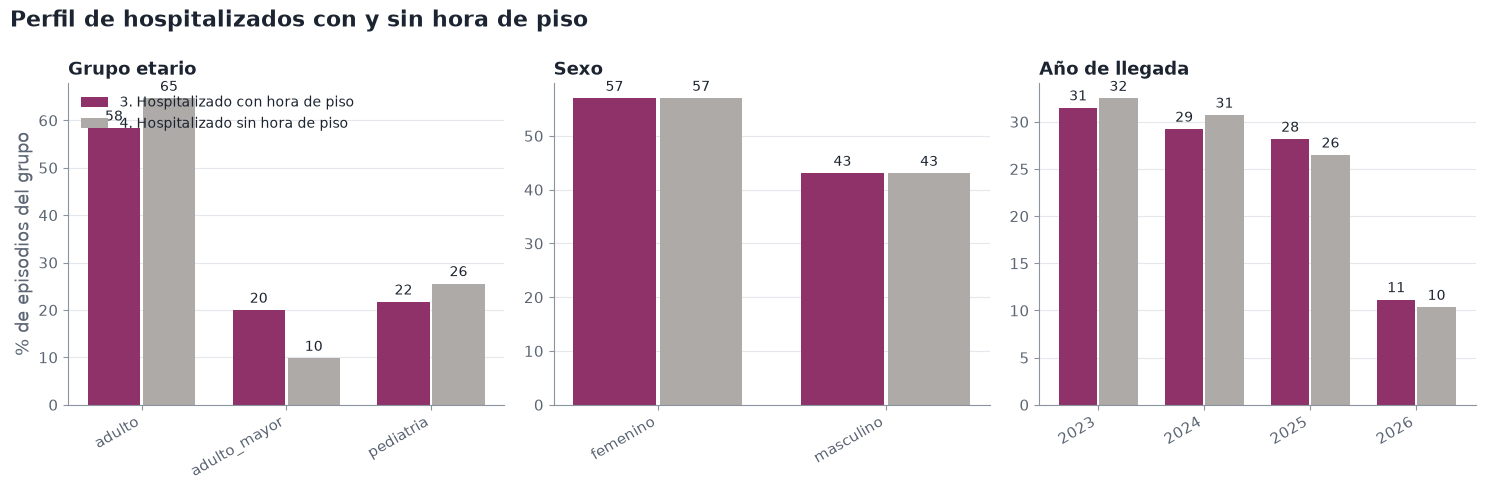

In [20]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
titulos = {'grupo_etario': 'Grupo etario', 'sexo': 'Sexo', 'anio_llegada': 'Año de llegada'}
for ax, (variable, titulo) in zip(ejes, titulos.items()):
    conteos = pd.crosstab(hospitalizados[variable], hospitalizados['grupo'])
    porcentajes = enmascarar_pequenos(100 * conteos / conteos.sum(), conteos)
    x = np.arange(len(porcentajes))
    for j, grupo in enumerate(porcentajes.columns):
        barras = ax.bar(x + (j - 0.5) * 0.38, porcentajes[grupo], width=0.36,
                        color=COLORES_GRUPO[grupo], label=ETIQUETAS_GRUPO[grupo])
        rotular_barras(ax, barras, porcentajes[grupo], formato='{:.0f}')
    ax.set_xticks(x, [str(v) for v in porcentajes.index], rotation=30, ha='right')
    ax.set_title(titulo, fontsize=13)
ejes[0].set_ylabel('% de episodios del grupo')
ejes[0].legend(fontsize=10, loc='upper left')
fig.suptitle('Perfil de hospitalizados con y sin hora de piso', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar_figura(fig, '02_hospitalizados_g3_vs_g4')
plt.show()

## 7. Exportación

El parquet de episodios contiene identificadores internos y solo se guarda en `data/interim/` (ignorado por git). Nunca se exporta a `reports/`.

In [21]:
nombre_base = f'episodios_urgencias_{config.UMBRAL_FUSION_MIN}min'
config.DATA_INTERIM.mkdir(parents=True, exist_ok=True)
episodios.to_parquet(config.DATA_INTERIM / f'{nombre_base}.parquet', index=False)

metadatos = {
    'umbral_fusion_min': config.UMBRAL_FUSION_MIN,
    'fecha_ejecucion': datetime.now().isoformat(timespec='seconds'),
    'n_filas': int(len(episodios)),
    'n_filas_por_grupo': {g: int(n) for g, n in tamano_grupos['n_episodios'].items()},
    'sql': 'sql/visitas_urgencias.sql',
    'sha256_sql': hash_sql('visitas_urgencias'),
    'fecha_corte_tendencias': str(config.FECHA_CORTE_TENDENCIAS),
    'ventanas_reconsulta': list(config.VENTANAS_RECONSULTA),
    'umbrales_los_h': config.UMBRALES_LOS_H,
}
with open(config.DATA_INTERIM / f'{nombre_base}.json', 'w', encoding='utf-8') as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2)
print('Exportado:', f'data/interim/{nombre_base}.parquet', 'y', f'data/interim/{nombre_base}.json')

Exportado: data/interim/episodios_urgencias_60min.parquet y data/interim/episodios_urgencias_60min.json
